# Orientação das fibras no slice YZ central

Este experimento mede a **orientação planar** dos segmentos de fibras visíveis no slice YZ central de `data/PPGF40.tif`. Os resultados não representam a orientação tridimensional das fibras completas. O eixo X é perpendicular a este plano: não é possível estimar a orientação em relação a X a partir de um único slice YZ.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import tifffile
from scipy.ndimage import binary_opening, find_objects
from scipy.interpolate import PchipInterpolator
from skimage.color import label2rgb
from skimage.measure import regionprops
from skimage.morphology import skeletonize

root = Path.cwd().resolve()
if not (root / 'data' / 'PPGF40.tif').is_file():
    root = root.parent
if not (root / 'data' / 'PPGF40.tif').is_file():
    raise FileNotFoundError('Execute o notebook na raiz do projeto ou em notebooks/; data/PPGF40.tif deve existir.')

import sys
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from fiber_analysis.config import SliceWiseConfig
from fiber_analysis.pipelines import SliceWiseFiberPipeline
from skimage.filters import threshold_otsu
from src_2d.utils.preprocessing import binarize_volume_otsu
from src_2d.utils.segmentation import segment_fibers_2d

## 1. Carregar e visualizar a imagem

O TIFF tem eixos `(Z, Y, X)`. Mapeamos o TIFF não comprimido em memória e copiamos somente o plano central em X, sem alocar o volume inteiro. Defina `y_range = (início, fim)` abaixo para selecionar o intervalo Y **[início, fim)** em pixels da imagem original. O padrão `(150, 820)` segue o recorte usado em `src_2d/testing.py` para `PPGF40.tif`; use `None` para manter todo o eixo Y. O recorte é aplicado antes de Otsu e da segmentação.

Slice YZ central: X = 310, Y = [150, 820), dimensões (Z, Y) = (1653, 670)


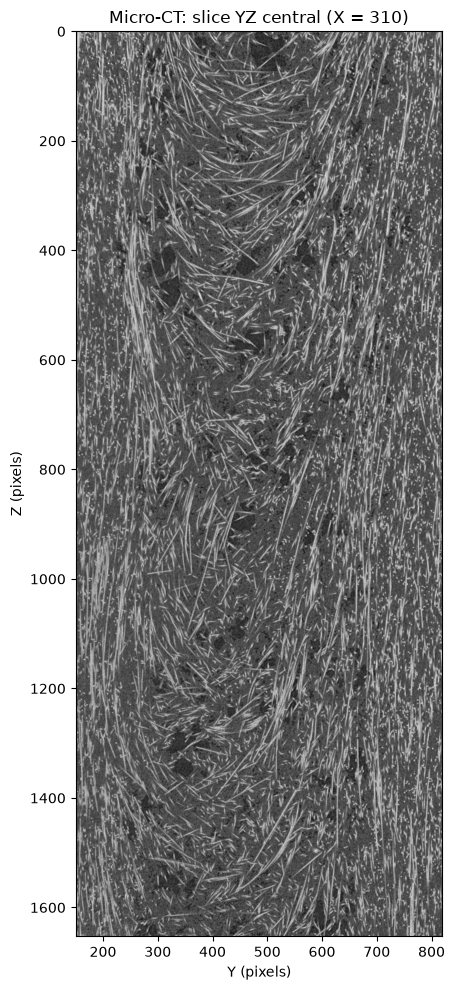

In [2]:
y_range = (150, 820)  # None para usar o eixo Y completo

volume = tifffile.memmap(root / 'data' / 'PPGF40.tif')
if volume.ndim != 3:
    raise ValueError('Esperado um TIFF 3D com eixos (Z, Y, X).')
if y_range is None:
    y_inicio, y_fim = 0, volume.shape[1]
elif (not isinstance(y_range, tuple) or len(y_range) != 2
      or any(not isinstance(v, int) or isinstance(v, bool) for v in y_range)):
    raise ValueError('y_range deve ser uma tupla (início, fim) de inteiros ou None.')
else:
    y_inicio, y_fim = y_range
if not 0 <= y_inicio < y_fim <= volume.shape[1]:
    raise ValueError(f'y_range deve satisfazer 0 <= início < fim <= {volume.shape[1]}.')
x_central = volume.shape[2] // 2
slice_yz = volume[:, y_inicio:y_fim, x_central].copy()
del volume

print(f'Slice YZ central: X = {x_central}, Y = [{y_inicio}, {y_fim}), dimensões (Z, Y) = {slice_yz.shape}')
plt.figure(figsize=(10, 10))
plt.imshow(slice_yz, cmap='gray', extent=(y_inicio, y_fim, slice_yz.shape[0], 0))
plt.title(f'Micro-CT: slice YZ central (X = {x_central})')
plt.xlabel('Y (pixels)')
plt.ylabel('Z (pixels)')
plt.tight_layout()
plt.show()

## 2. Binarizar e segmentar em 2D

Reproduzimos a sequência de `src_2d`: (1) binarização por Otsu; (2) abertura morfológica; (3) esqueletização e remoção de ramos curtos; (4) poda por continuidade angular nas junções; (5) rotulagem dos componentes do esqueleto; (6) expansão dos rótulos por watershed. A função `segment_fibers_2d` implementa as etapas 3–6, sem copiar sua lógica para o notebook. Como este experimento usa **um único plano YZ**, Otsu e abertura são aplicados em **2D** ao corte, ao contrário do pré-processamento 3D do pipeline completo. Não há propagação de rótulos entre cortes.

Os parâmetros ficam centralizados em `config_pipeline` (`SliceWiseConfig`), reutilizada no processamento volumétrico da seção 7. Para os planos individuais, extraímos somente os argumentos aceitos por `segment_fibers_2d`. Não usamos `SliceWiseFiberPipeline` em um volume de uma única camada: sua abertura 3D alteraria o processamento planar.

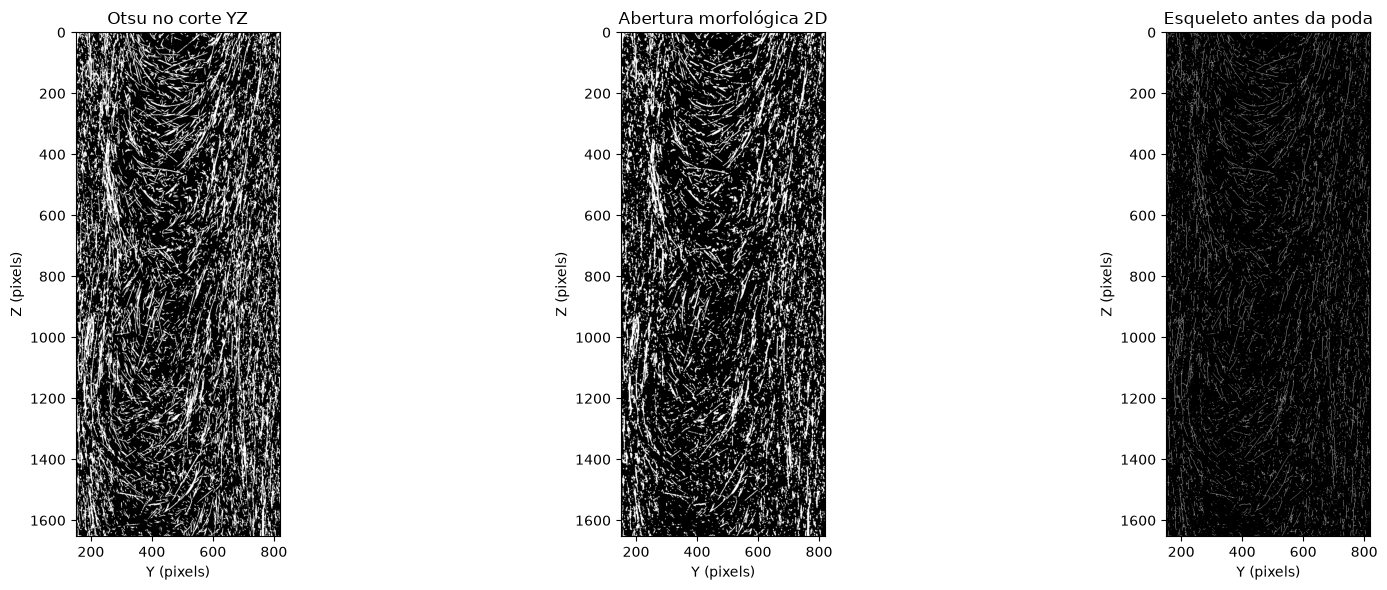

Limiar de Otsu: 27489; segmentos rotulados: 574


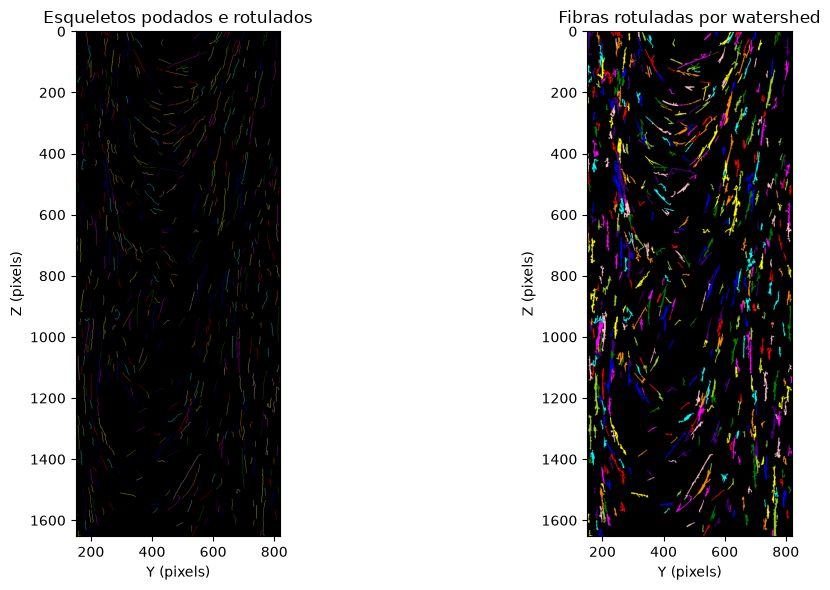

In [3]:
mascara_otsu, limiar = binarize_volume_otsu(slice_yz)
mascara = binary_opening(mascara_otsu)
esqueleto_inicial = skeletonize(mascara)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, image, title in zip(
    axes,
    (mascara_otsu, mascara, esqueleto_inicial),
    ('Otsu no corte YZ', 'Abertura morfológica 2D', 'Esqueleto antes da poda'),
):
    ax.imshow(image, cmap='gray', extent=(y_inicio, y_fim, slice_yz.shape[0], 0))
    ax.set_title(title)
    ax.set_xlabel('Y (pixels)')
    ax.set_ylabel('Z (pixels)')
fig.tight_layout()
plt.show()

config_pipeline = SliceWiseConfig(
    slicing_axis='z', max_angle_deviation=45, remove_small_skeletons=True,
    min_skeleton_size=20, min_branch_length=10,
    local_analysis=True, local_range=12,
    propagation_min_overlap=1, propagation_min_overlap_ratio=0.0,
)
parametros_segmentacao = {
    campo: getattr(config_pipeline, campo)
    for campo in (
        'max_angle_deviation', 'remove_small_skeletons', 'min_skeleton_size',
        'min_branch_length', 'local_analysis', 'local_range',
    )
}
fibras, esqueletos = segment_fibers_2d(mascara, **parametros_segmentacao)
print(f'Limiar de Otsu: {limiar}; segmentos rotulados: {len(np.unique(esqueletos)) - 1}')
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, image, title in zip(
    axes,
    (label2rgb(esqueletos, bg_label=0), label2rgb(fibras, bg_label=0)),
    ('Esqueletos podados e rotulados', 'Fibras rotuladas por watershed'),
):
    ax.imshow(image, cmap='gray' if image.ndim == 2 else None,
              extent=(y_inicio, y_fim, slice_yz.shape[0], 0))
    ax.set_title(title)
    ax.set_xlabel('Y (pixels)')
    ax.set_ylabel('Z (pixels)')
fig.tight_layout()
plt.show()

## 3. Orientação no plano YZ

Para cada componente do esqueleto, a primeira direção principal (PCA/SVD) das coordenadas `(z, y)` define um **eixo sem sentido**. Medimos `θ_Z = arccos(|v_z|)`, entre 0° e 90°. Componentes com menos de dois pixels ou sem dispersão espacial não têm orientação definida. A mesma função de medição será usada em cada faixa Y.

In [4]:
def medir_orientacoes_z(esqueletos_rotulados, descricao, y_offset=0):
    medidas = []
    n_invalidos = 0
    for regiao in regionprops(esqueletos_rotulados):
        coordenadas = regiao.coords.astype(float)
        if len(coordenadas) < 2:
            n_invalidos += 1
            continue
        centradas = coordenadas - coordenadas.mean(axis=0)
        _, valores, direcoes = np.linalg.svd(centradas, full_matrices=False)
        if valores[0] <= 0:
            n_invalidos += 1
            continue
        cos_z = np.clip(abs(direcoes[0, 0]), 0.0, 1.0)
        medidas.append({'rotulo': regiao.label, 'pixels_esqueleto': len(coordenadas),
                        'centroide_y': coordenadas[:, 1].mean() + y_offset,
                        'angulo_z_graus': np.degrees(np.arccos(cos_z))})
    if not medidas:
        raise ValueError(f'Nenhuma fibra com orientação definida em {descricao}; não é possível calcular Hermans.')
    return pd.DataFrame(medidas), n_invalidos

orientacoes, n_invalidos = medir_orientacoes_z(esqueletos, 'todo o slice', y_offset=y_inicio)
print(f'Fibras válidas: {len(orientacoes)}; componentes excluídos: {n_invalidos}')
display(orientacoes)
fig = go.Figure(go.Histogram(x=orientacoes['angulo_z_graus'], xbins=dict(start=0, end=90, size=5)))
fig.update_layout(
    title='Orientação planar dos esqueletos',
    xaxis_title='Ângulo axial em relação a Z (graus)',
    yaxis_title='Número de fibras',
    bargap=0.05,
)
fig.show()

Fibras válidas: 574; componentes excluídos: 0


,rotulo,pixels_esqueleto,centroide_y,angulo_z_graus
0,3,58,248.465517,70.104198
1,6,20,572.600000,29.864722
2,8,51,606.274510,35.853019
3,9,22,648.818182,24.304093
4,11,37,773.594595,10.068905
...,...,...,...,...
569,3232,21,528.476190,1.571736
570,3242,33,538.969697,28.548609
571,3256,29,195.586207,13.093868
572,3270,25,159.800000,20.638549


## 4. Parâmetro de ordem de Hermans planar

Cada fibra válida contribui igualmente: $S_Z = 2\langle\cos^2\theta_Z\rangle - 1$. Assim, $S_Z=1$ indica alinhamento com Z, $S_Z=0$ isotropia no plano e $S_Z=-1$ alinhamento com Y. Não aplicar a fórmula 3D a orientações medidas num único slice.

In [5]:
def calcular_hermans_z(orientacoes_z):
    angulos_rad = np.deg2rad(orientacoes_z['angulo_z_graus'].to_numpy())
    return 2 * np.mean(np.cos(angulos_rad) ** 2) - 1

hermans_z = calcular_hermans_z(orientacoes)
print(f'Parâmetro de ordem de Hermans planar (eixo Z): {hermans_z:.6f}')

Parâmetro de ordem de Hermans planar (eixo Z): 0.664769


## 5. Hermans por faixa Y

Ajuste `y_proportions` para definir a fração do `y_range` destinada a cada região, na ordem do dicionário. As proporções devem ser positivas e somar **1**; as fronteiras são arredondadas para pixels e a última coincide exatamente com o fim de `y_range`. `y_intervals` contém os intervalos resultantes **[início, fim)** nas coordenadas Y originais. O slice é segmentado **por completo** (seção 2: um único Otsu, abertura 2D e `segment_fibers_2d`) e só depois subdividido: cada fibra segmentada é atribuída à faixa que contém o **centróide Y** do seu esqueleto. Assim, fibras que cruzam fronteiras não são cortadas e cada fibra pertence a uma única faixa. O gráfico posiciona cada medida no **centro de sua faixa** e interpola os valores com uma spline cúbica preservadora de forma (PCHIP), somente entre os centros medidos; a curva não representa medições contínuas do material.

Intervalos Y calculados: {'left_skin': (150, 250), 'left_transition': (250, 351), 'core': (351, 619), 'right_transition': (619, 720), 'right_skin': (720, 820)}


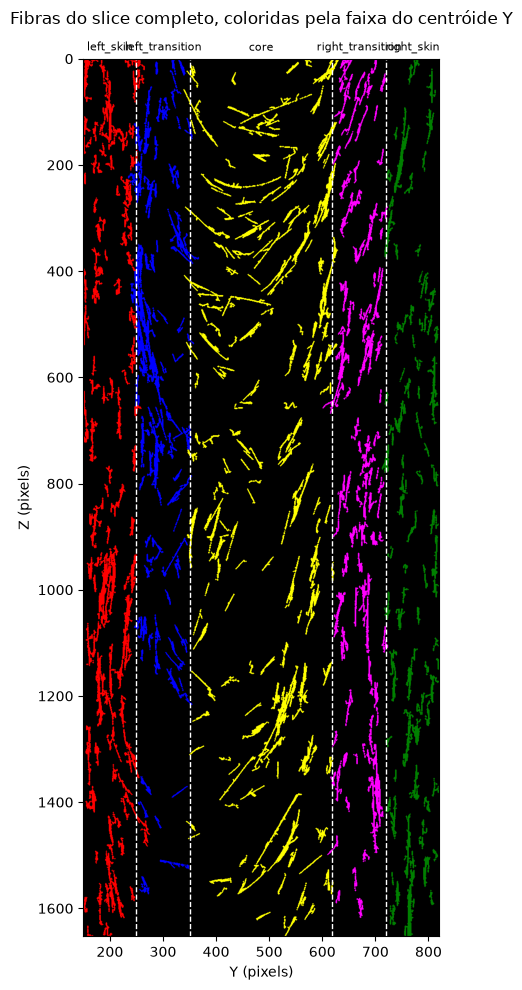

,regiao,y_inicio,y_fim,n_fibras,hermans_z
0,left_skin,150,250,114,0.904340
1,left_transition,250,351,88,0.771512
2,core,351,619,194,0.243872
3,right_transition,619,720,92,0.903660
4,right_skin,720,820,86,0.931883


In [7]:
y_proportions = {
    'left_skin': 0.15,
    'left_transition': 0.15,
    'core': 0.40,
    'right_transition': 0.15,
    'right_skin': 0.15,
}

if len(y_proportions) < 2:
    raise ValueError('Defina ao menos duas regiões Y para interpolar uma spline entre os pontos.')
if any(not isinstance(fracao, (int, float)) or isinstance(fracao, bool)
       or not np.isfinite(fracao) or fracao <= 0 for fracao in y_proportions.values()):
    raise ValueError('As proporções Y devem ser números positivos e finitos.')
if not np.isclose(sum(y_proportions.values()), 1.0, rtol=0, atol=1e-9):
    raise ValueError('As proporções Y devem somar 1.')

largura_y = y_fim - y_inicio
limites_y = [y_inicio]
acumulado = 0.0
for fracao in list(y_proportions.values())[:-1]:
    acumulado += fracao
    limites_y.append(y_inicio + round(largura_y * acumulado))
limites_y.append(y_fim)
if any(inicio >= fim for inicio, fim in zip(limites_y[:-1], limites_y[1:])):
    raise ValueError('Uma região Y ficou vazia após arredondar as proporções para pixels.')
y_intervals = dict(zip(y_proportions, zip(limites_y[:-1], limites_y[1:])))
print('Intervalos Y calculados:', y_intervals)
anterior_fim = y_inicio
for nome, intervalo in y_intervals.items():
    if (not isinstance(intervalo, (tuple, list)) or len(intervalo) != 2
        or any(not isinstance(v, int) or isinstance(v, bool) for v in intervalo)):
        raise ValueError('Cada intervalo deve ser um par (início, fim) de inteiros.')
    inicio, fim = intervalo
    if not y_inicio <= anterior_fim <= inicio < fim <= y_fim:
        raise ValueError(f'Intervalo {nome}: {intervalo} fora de y_range ou sobreposto/fora de ordem.')
    anterior_fim = fim

limites_internos_y = [fim for _, fim in y_intervals.values()][:-1]


def hermans_por_faixa(orientacoes_plano):
    nomes_faixas = np.array(list(y_intervals))
    faixa_por_fibra = nomes_faixas[np.digitize(orientacoes_plano['centroide_y'], limites_internos_y)]
    resultados = []
    for nome, (inicio, fim) in y_intervals.items():
        fibras_na_faixa = orientacoes_plano[faixa_por_fibra == nome]
        resultados.append({'regiao': nome, 'y_inicio': inicio, 'y_fim': fim,
                           'n_fibras': len(fibras_na_faixa),
                           'hermans_z': calcular_hermans_z(fibras_na_faixa) if len(fibras_na_faixa) else np.nan})
    return resultados, faixa_por_fibra


resultados_faixas, faixa_por_fibra = hermans_por_faixa(orientacoes)
mapa_faixas = np.zeros(esqueletos.shape, dtype=int)
for indice_faixa, nome in enumerate(y_intervals, start=1):
    for rotulo in orientacoes.loc[faixa_por_fibra == nome, 'rotulo']:
        mapa_faixas[fibras == rotulo] = indice_faixa
fig, ax = plt.subplots(figsize=(8, 10))
ax.imshow(label2rgb(mapa_faixas, bg_label=0), extent=(y_inicio, y_fim, slice_yz.shape[0], 0))
for limite in limites_internos_y:
    ax.axvline(limite, color='white', linestyle='--', linewidth=1)
for nome, (inicio, fim) in y_intervals.items():
    ax.text((inicio + fim) / 2, -10, nome, ha='center', va='bottom', fontsize=8)
ax.set_title('Fibras do slice completo, coloridas pela faixa do centróide Y', pad=25)
ax.set_xlabel('Y (pixels)')
ax.set_ylabel('Z (pixels)')
fig.tight_layout()
plt.show()

resultados_faixas = pd.DataFrame(resultados_faixas)
display(resultados_faixas)
centros_y = (resultados_faixas['y_inicio'].to_numpy() + resultados_faixas['y_fim'].to_numpy()) / 2
valores_z = resultados_faixas['hermans_z'].to_numpy()
validos = np.isfinite(valores_z)
centros_y, valores_z = centros_y[validos], valores_z[validos]
spline = PchipInterpolator(centros_y, valores_z)
y_continuo = np.linspace(centros_y[0], centros_y[-1], 300)
fig = go.Figure()
fig.add_trace(
    go.Scatter(x=y_continuo, y=spline(y_continuo), mode='lines', name='Spline cúbica (PCHIP)')
)
fig.add_trace(
    go.Scatter(
        x=centros_y,
        y=valores_z,
        mode='markers',
        name='Hermans por faixa',
        text=resultados_faixas['regiao'][validos],
        marker={'size': 10, 'color': 'darkorange', 'line': {'color': 'black', 'width': 1}},
    )
)
fig.update_layout(
    title='Parâmetro de ordem de Hermans por faixa Y',
    xaxis={
        'title': 'Centro da faixa Y (pixels da imagem original)',
        'tickmode': 'array',
        'tickvals': centros_y,
        'ticktext': list(resultados_faixas['regiao'][validos]),
    },
    yaxis={'title': 'Hermans planar em relação a Z', 'range': [0.1, 1]},
)
fig.show()

## 6. Média de Hermans nas 400 camadas centrais

Processamos 400 planos YZ consecutivos centrados no eixo **X**. Cada camada é binarizada (Otsu da camada), aberta e segmentada **por completo** com os parâmetros da seção 2; depois as fibras são distribuídas nas faixas proporcionais de Y pelo centróide Y e medimos Hermans planar em relação a **Z** para cada faixa (NaN se a faixa não tiver fibras naquela camada, ignorado na média). A média por faixa é a média aritmética dos 400 parâmetros calculados, **sem ponderar pelo número de fibras**. O processamento pode demorar; o TIFF é mapeado em memória para ler somente a camada corrente. A curva no gráfico é uma interpolação dos cinco valores médios, não uma medição contínua.

In [8]:
from tqdm.auto import tqdm

n_camadas_centrais = 400
volume = tifffile.memmap(root / 'data' / 'PPGF40.tif')
if volume.ndim != 3 or volume.shape[0] != slice_yz.shape[0] or volume.shape[1] < y_fim:
    raise ValueError('As dimensões do TIFF mudaram desde a leitura do slice central.')
if not isinstance(n_camadas_centrais, int) or isinstance(n_camadas_centrais, bool) or not 1 <= n_camadas_centrais <= volume.shape[2]:
    raise ValueError(f'n_camadas_centrais deve ser um inteiro entre 1 e {volume.shape[2]}.')
x_inicio = (volume.shape[2] - n_camadas_centrais) // 2
x_fim = x_inicio + n_camadas_centrais
print(f'Analisando X=[{x_inicio}, {x_fim}) ({n_camadas_centrais} camadas YZ).')

resultados_camadas = []
for x in tqdm(range(x_inicio, x_fim), desc='Camadas YZ'):
    camada = volume[:, y_inicio:y_fim, x]
    binaria, _ = binarize_volume_otsu(camada)
    _, esqueletos_camada = segment_fibers_2d(binary_opening(binaria), **parametros_segmentacao)
    orientacoes_camada, _ = medir_orientacoes_z(esqueletos_camada, f'X={x}', y_offset=y_inicio)
    for resultado in hermans_por_faixa(orientacoes_camada)[0]:
        resultados_camadas.append({'x': x, 'regiao': resultado['regiao'],
                                   'n_fibras': resultado['n_fibras'],
                                   'hermans_z': resultado['hermans_z']})
del volume

resultados_camadas = pd.DataFrame(resultados_camadas)
medias_faixas = resultados_camadas.groupby('regiao', sort=False).agg(
    media_hermans_z=('hermans_z', 'mean'),
    desvio_padrao=('hermans_z', 'std'),
    n_camadas=('x', 'nunique'),
    n_camadas_com_fibras=('hermans_z', 'count'),
    n_fibras_total=('n_fibras', 'sum'),
).reindex(y_intervals)
if (medias_faixas['n_camadas'] != n_camadas_centrais).any():
    raise ValueError('Nem todas as faixas têm uma medida por camada.')
display(medias_faixas)

centros_faixas = np.array([(inicio + fim) / 2 for inicio, fim in y_intervals.values()])
spline_media = PchipInterpolator(centros_faixas, medias_faixas['media_hermans_z'].to_numpy())
y_suave = np.linspace(centros_faixas[0], centros_faixas[-1], 300)
fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=y_suave, y=spline_media(y_suave), mode='lines', name='Spline cúbica das médias (PCHIP)'
    )
)
fig.add_trace(
    go.Scatter(
        x=centros_faixas,
        y=medias_faixas['media_hermans_z'],
        mode='markers',
        name='Média por faixa',
        text=list(y_intervals),
        error_y={
            'type': 'data',
            'array': medias_faixas['desvio_padrao'],
            'visible': True,
        },
        marker={
            'size': 10,
            'color': 'darkorange',
            'line': {'color': 'black', 'width': 1},
        },
    )
)
fig.update_layout(
    title=f'Hermans médio por faixa Y — {n_camadas_centrais} camadas centrais',
    xaxis={
        'title': 'Centro da faixa Y (pixels da imagem original)',
        'tickmode': 'array',
        'tickvals': centros_faixas,
        'ticktext': list(y_intervals),
    },
    yaxis={
        'title': 'Média de Hermans planar em relação a Z',
        'range': [0.4, 1],
    },
)

fig.show()

/home/hbcastro/miniforge3/envs/my_vedo_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Analisando X=[110, 510) (400 camadas YZ).


Camadas YZ: 100%|██████████| 400/400 [04:25<00:00,  1.51it/s]


,media_hermans_z,desvio_padrao,n_camadas,n_camadas_com_fibras,n_fibras_total
regiao,,,,,
left_skin,0.868783,0.092925,400,400,42110
left_transition,0.725525,0.143362,400,400,41647
core,0.613622,0.231346,400,397,101198
right_transition,0.777819,0.132082,400,400,43575
right_skin,0.869908,0.091026,400,400,42389


## 7. Hermans 3D por blocos: segmentação planar + propagação 3D

Mesmo fluxo de `src_2d/testing.py`, aplicado a **blocos** em vez da ROI inteira. A ROI (`roi_3d`, padrão de `testing.py`: Y=150:820, X=129:491, Z inteiro) é dividida em faixas Y pelas mesmas proporções `y_proportions` da seção 5. Cada faixa é dividida em blocos de `tamanho_bloco['z']` × `tamanho_bloco['x']` voxels (padrão 200 × 200), com a largura da faixa em Y. A grade é centrada na ROI e os restos que não formam um bloco completo são descartados.

Em cada bloco, `SliceWiseFiberPipeline(config_pipeline).segment(bloco)` recebe os tons de cinza e executa: (1) Otsu **global no bloco** e abertura morfológica **3D**; (2) segmentação 2D plano a plano; (3) propagação dos rótulos entre camadas. Na convenção preservada do código, `slicing_axis="z"` percorre `volume[:, :, i]`, ou seja, os **planos YZ ao longo de X**. O volume reconciliado é obtido em `resultado_bloco.labels` e usado no cálculo de Hermans 3D. Não binarizamos nem aplicamos abertura antes de chamar a classe. A métrica de cada faixa é a **média dos blocos** dessa faixa. Os blocos são lidos do TIFF mapeado em memória, um por vez; não há normalização adicional.

Intervalos Y (ROI 3D): {'left_skin': (150, 250), 'left_transition': (250, 351), 'core': (351, 619), 'right_transition': (619, 720), 'right_skin': (720, 820)}
Blocos Z: [(26, 226), (226, 426), (426, 626), (626, 826), (826, 1026), (1026, 1226), (1226, 1426), (1426, 1626)]
Blocos X: [(210, 410)]
8 blocos por faixa; 40 blocos no total.


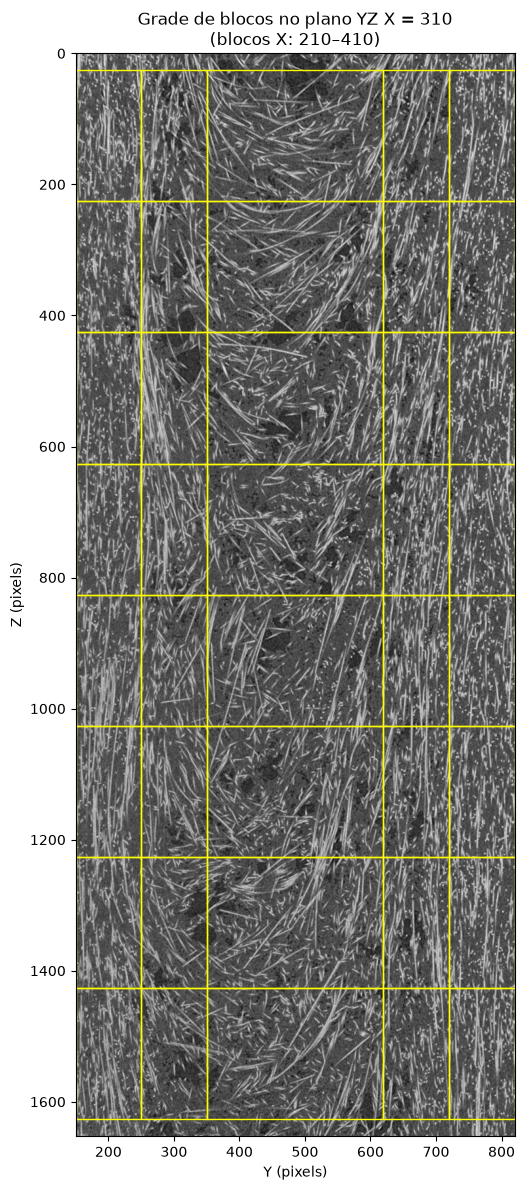

In [9]:
roi_3d = {
    'z': (None, None),
    'y': (150, 820),
    'x': (129, 491),
}
tamanho_bloco = {'z': 200, 'x': 200}

volume = tifffile.memmap(root / 'data' / 'PPGF40.tif')
if volume.ndim != 3:
    raise ValueError('Esperado um TIFF 3D com eixos (Z, Y, X).')
limites_roi = {}
for eixo, tamanho in zip('zyx', volume.shape):
    intervalo = roi_3d.get(eixo)
    if not isinstance(intervalo, tuple) or len(intervalo) != 2:
        raise ValueError(f'roi_3d[{eixo!r}] deve ser uma tupla (início, fim).')
    inicio, fim = (0 if intervalo[0] is None else intervalo[0],
                   tamanho if intervalo[1] is None else intervalo[1])
    if any(not isinstance(v, int) or isinstance(v, bool) for v in (inicio, fim)) or not 0 <= inicio < fim <= tamanho:
        raise ValueError(f'roi_3d[{eixo!r}] deve satisfazer 0 <= início < fim <= {tamanho}.')
    limites_roi[eixo] = (inicio, fim)
(z0_3d, z1_3d), (y0_3d, y1_3d), (x0_3d, x1_3d) = limites_roi['z'], limites_roi['y'], limites_roi['x']

largura_y_3d = y1_3d - y0_3d
limites_y_3d = [y0_3d]
acumulado = 0.0
for fracao in list(y_proportions.values())[:-1]:
    acumulado += fracao
    limites_y_3d.append(y0_3d + round(largura_y_3d * acumulado))
limites_y_3d.append(y1_3d)
if any(inicio >= fim for inicio, fim in zip(limites_y_3d[:-1], limites_y_3d[1:])):
    raise ValueError('Uma região Y da ROI 3D ficou vazia após arredondar as proporções.')
y_intervals_3d = dict(zip(y_proportions, zip(limites_y_3d[:-1], limites_y_3d[1:])))


def grade_blocos(inicio, fim, tamanho, eixo):
    if not isinstance(tamanho, int) or isinstance(tamanho, bool) or not 2 <= tamanho <= fim - inicio:
        raise ValueError(f'tamanho_bloco[{eixo!r}] deve ser um inteiro entre 2 e {fim - inicio}.')
    n_blocos = (fim - inicio) // tamanho
    deslocamento = inicio + ((fim - inicio) - n_blocos * tamanho) // 2
    return [(deslocamento + k * tamanho, deslocamento + (k + 1) * tamanho) for k in range(n_blocos)]


blocos_z = grade_blocos(z0_3d, z1_3d, tamanho_bloco['z'], 'z')
blocos_x = grade_blocos(x0_3d, x1_3d, tamanho_bloco['x'], 'x')
print('Intervalos Y (ROI 3D):', y_intervals_3d)
print(f'Blocos Z: {blocos_z}')
print(f'Blocos X: {blocos_x}')
print(f'{len(blocos_z) * len(blocos_x)} blocos por faixa; '
      f'{len(blocos_z) * len(blocos_x) * len(y_intervals_3d)} blocos no total.')

x_vis = (blocos_x[0][0] + blocos_x[-1][1]) // 2
plano_vis = np.asarray(volume[z0_3d:z1_3d, y0_3d:y1_3d, x_vis])
del volume
fig, ax = plt.subplots(figsize=(7, 12))
ax.imshow(plano_vis, cmap='gray', extent=(y0_3d, y1_3d, z1_3d, z0_3d))
for inicio_y, fim_y in y_intervals_3d.values():
    for inicio_z, fim_z in blocos_z:
        ax.add_patch(plt.Rectangle((inicio_y, inicio_z), fim_y - inicio_y, fim_z - inicio_z,
                                   fill=False, edgecolor='yellow', linewidth=1))
ax.set_title(f'Grade de blocos no plano YZ X = {x_vis}\n'
             f'(blocos X: {blocos_x[0][0]}–{blocos_x[-1][1]})')
ax.set_xlabel('Y (pixels)')
ax.set_ylabel('Z (pixels)')
fig.tight_layout()
plt.show()

### 7.1 Orientação 3D e Hermans em relação a Z

Para cada fibra 3D, a direção é o primeiro eixo principal (PCA/SVD) das coordenadas `(z, y, x)` de seus voxels, obtidas dentro da caixa delimitadora (`find_objects`). Com $\cos\theta_Z = |d_z|$, o parâmetro de Hermans 3D é

$$f_Z = \frac{3\langle\cos^2\theta_Z\rangle - 1}{2},$$

com cada fibra pesando igualmente: $f_Z=1$ (paralelas a Z), $0$ (isotrópico 3D) e $-0{,}5$ (perpendiculares a Z). Descartam-se fibras com menos de `min_voxels_fibra` voxels ou presentes em menos de `min_planos_x` planos YZ (estas não têm informação sobre a componente X). A célula também valida as funções com cilindros sintéticos.

Mantemos estas métricas específicas do experimento: PCA/SVD dos voxels da fibra, centróides e filtros por volume/extensão em X. Não as substituímos por `fiber_analysis.metrics.measure_fibers`, que estima a orientação pelos endpoints do esqueleto e mudaria a análise de Hermans.

In [10]:
min_voxels_fibra = 100
min_planos_x = 2


def medir_orientacoes_3d(rotulos, origem=(0, 0, 0), min_voxels=1, min_planos=1):
    medidas = []
    descartadas = 0
    for indice, caixa in enumerate(find_objects(rotulos), start=1):
        if caixa is None:
            continue
        if caixa[2].stop - caixa[2].start < min_planos:
            descartadas += 1
            continue
        coords = np.argwhere(rotulos[caixa] == indice)
        if len(coords) < min_voxels:
            descartadas += 1
            continue
        coords = coords + np.array([s.start for s in caixa])
        centro = coords.mean(axis=0)
        centradas = coords - centro
        if not np.any(centradas):
            descartadas += 1
            continue
        direcao = np.linalg.svd(centradas, full_matrices=False)[2][0]
        cos_z = min(abs(direcao[0]), 1.0)
        medidas.append({'rotulo': indice, 'n_voxels': len(coords),
                        'n_planos_x': caixa[2].stop - caixa[2].start,
                        'centroide_z': centro[0] + origem[0],
                        'centroide_y': centro[1] + origem[1],
                        'centroide_x': centro[2] + origem[2],
                        'd_z': direcao[0], 'd_y': direcao[1], 'd_x': direcao[2],
                        'theta_z_graus': np.degrees(np.arccos(cos_z))})
    return pd.DataFrame(medidas), descartadas


def calcular_hermans_3d_z(orientacoes):
    if len(orientacoes) == 0:
        return np.nan
    cos2 = np.cos(np.deg2rad(orientacoes['theta_z_graus'].to_numpy())) ** 2
    return (3 * np.mean(cos2) - 1) / 2


def _cilindros_sinteticos(direcoes, forma=(60, 60, 60), raio=1.5, comprimento=20, semente=0):
    rng = np.random.default_rng(semente)
    rotulos = np.zeros(forma, dtype=np.uint32)
    grade = np.indices(forma).reshape(3, -1).T
    for indice, direcao in enumerate(direcoes, start=1):
        direcao = np.asarray(direcao, float) / np.linalg.norm(direcao)
        centro = rng.uniform(comprimento, np.array(forma) - comprimento)
        rel = grade - centro
        t = rel @ direcao
        dist = np.linalg.norm(rel - np.outer(t, direcao), axis=1)
        dentro = (np.abs(t) <= comprimento / 2) & (dist <= raio)
        rotulos.reshape(-1)[dentro] = indice
    return rotulos


_rng = np.random.default_rng(1)
_isotropicas = _rng.normal(size=(300, 3))
for nome_teste, direcoes, esperado in [
    ('paralelas a Z', [(1, 0, 0)] * 5, 1.0),
    ('paralelas a Y', [(0, 1, 0)] * 5, -0.5),
    ('paralelas a X', [(0, 0, 1)] * 5, -0.5),
]:
    df_teste, _ = medir_orientacoes_3d(_cilindros_sinteticos(direcoes))
    f_teste = calcular_hermans_3d_z(df_teste)
    if len(df_teste) != len(direcoes) or not np.isclose(f_teste, esperado, atol=0.05):
        raise AssertionError(f'Validação sintética falhou ({nome_teste}): f = {f_teste:.3f}')
    print(f'Validação {nome_teste}: f_Z = {f_teste:.3f} (esperado {esperado})')
_df_iso = pd.DataFrame({'theta_z_graus': np.degrees(np.arccos(np.abs(
    _isotropicas[:, 0] / np.linalg.norm(_isotropicas, axis=1))))})
print(f'Validação isotrópica (direções aleatórias): f_Z = {calcular_hermans_3d_z(_df_iso):.3f} (esperado ~0)')

Validação paralelas a Z: f_Z = 1.000 (esperado 1.0)
Validação paralelas a Y: f_Z = -0.500 (esperado -0.5)
Validação paralelas a X: f_Z = -0.500 (esperado -0.5)
Validação isotrópica (direções aleatórias): f_Z = -0.007 (esperado ~0)


### 7.2 Processamento dos blocos

Uma instância de `SliceWiseFiberPipeline` é reutilizada para todos os blocos com a configuração `config_pipeline` da seção 2, incluindo `propagation_min_overlap=1` e `propagation_min_overlap_ratio=0.0`. Usamos `verbose=False` para manter somente a barra externa por bloco, sem mensagens ou barras internas repetidas; avisos e exceções continuam visíveis. Cada bloco gera uma linha em `resultados_blocos_3d` com seu $f_Z$; as orientações de todas as fibras ficam em `orientacoes_3d`. O limiar de Otsu é recalculado somente para preservar a coluna `limiar_otsu` do relatório, pois o resultado da classe não exporta esse valor; isso não reaplica a binarização nem a abertura. Um bloco do `core` é exibido como exemplo.

Blocos 3D: 100%|██████████| 40/40 [03:42<00:00,  5.56s/it]


,regiao,y_inicio,y_fim,z_inicio,z_fim,x_inicio,x_fim,limiar_otsu,n_rotulos,n_fibras,n_descartadas,hermans_3d_z
0,left_skin,150,250,26,226,210,410,27663,785,439,346,0.943410
1,left_skin,150,250,226,426,210,410,27585,742,415,327,0.947385
2,left_skin,150,250,426,626,210,410,27549,835,442,393,0.965055
3,left_skin,150,250,626,826,210,410,27518,809,459,350,0.951500
4,left_skin,150,250,826,1026,210,410,27476,854,484,370,0.947725
5,left_skin,150,250,1026,1226,210,410,27450,851,473,378,0.955775
6,left_skin,150,250,1226,1426,210,410,27410,949,517,432,0.948812
7,left_skin,150,250,1426,1626,210,410,27403,794,454,340,0.955509
8,left_transition,250,351,26,226,210,410,27530,891,498,393,0.848473
9,left_transition,250,351,226,426,210,410,27511,970,524,446,0.830994


Fibras 3D válidas em todos os blocos: 26222


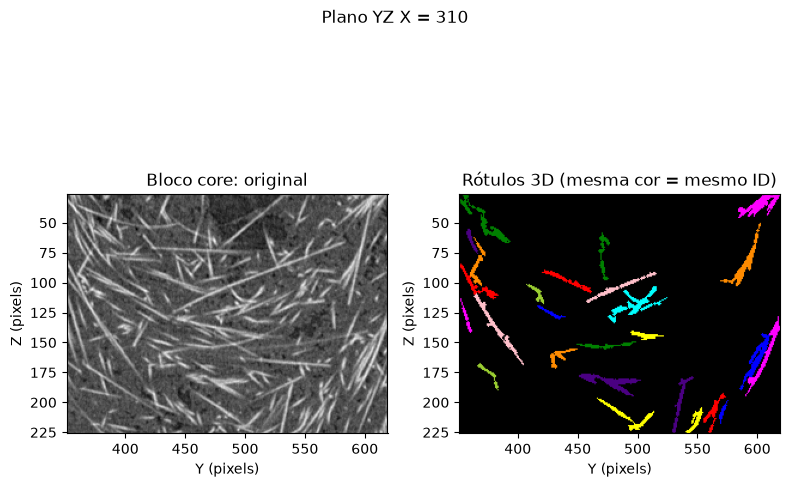

In [11]:
from tqdm.auto import tqdm

pipeline_blocos = SliceWiseFiberPipeline(config_pipeline, verbose=False)
regiao_exemplo = 'core' if 'core' in y_intervals_3d else next(iter(y_intervals_3d))

volume = tifffile.memmap(root / 'data' / 'PPGF40.tif')
lista_blocos = [(nome, faixa_y, bz, bx) for nome, faixa_y in y_intervals_3d.items()
                for bz in blocos_z for bx in blocos_x]
resultados_blocos_3d = []
orientacoes_blocos = []
exemplo_bloco = None
for nome, (inicio_y, fim_y), (inicio_z, fim_z), (inicio_x, fim_x) in tqdm(lista_blocos, desc='Blocos 3D'):
    bloco = np.asarray(volume[inicio_z:fim_z, inicio_y:fim_y, inicio_x:fim_x])
    resultado_bloco = pipeline_blocos.segment(bloco)
    rotulos_bloco = resultado_bloco.labels
    limiar_bloco = threshold_otsu(bloco)
    orientacoes_bloco, descartadas = medir_orientacoes_3d(
        rotulos_bloco, origem=(inicio_z, inicio_y, inicio_x),
        min_voxels=min_voxels_fibra, min_planos=min_planos_x,
    )
    resultados_blocos_3d.append({'regiao': nome, 'y_inicio': inicio_y, 'y_fim': fim_y,
                                 'z_inicio': inicio_z, 'z_fim': fim_z,
                                 'x_inicio': inicio_x, 'x_fim': fim_x,
                                 'limiar_otsu': limiar_bloco,
                                 'n_rotulos': int(rotulos_bloco.max()),
                                 'n_fibras': len(orientacoes_bloco),
                                 'n_descartadas': descartadas,
                                 'hermans_3d_z': calcular_hermans_3d_z(orientacoes_bloco)})
    if len(orientacoes_bloco):
        orientacoes_blocos.append(orientacoes_bloco.assign(regiao=nome, z_bloco=inicio_z, x_bloco=inicio_x))
    if exemplo_bloco is None and nome == regiao_exemplo:
        meio_x = rotulos_bloco.shape[2] // 2
        exemplo_bloco = {'original': bloco[:, :, meio_x], 'rotulos': rotulos_bloco[:, :, meio_x],
                         'extent': (inicio_y, fim_y, fim_z, inicio_z), 'x': inicio_x + meio_x}
    del bloco, resultado_bloco, rotulos_bloco
del volume

resultados_blocos_3d = pd.DataFrame(resultados_blocos_3d)
orientacoes_3d = (pd.concat(orientacoes_blocos, ignore_index=True) if orientacoes_blocos
                  else pd.DataFrame(columns=['regiao', 'theta_z_graus']))
display(resultados_blocos_3d)
print(f'Fibras 3D válidas em todos os blocos: {len(orientacoes_3d)}')

fig, axes = plt.subplots(1, 2, figsize=(8, 6))
axes[0].imshow(exemplo_bloco['original'], cmap='gray', extent=exemplo_bloco['extent'])
axes[0].set_title(f'Bloco {regiao_exemplo}: original')
axes[1].imshow(label2rgb(exemplo_bloco['rotulos'], bg_label=0), extent=exemplo_bloco['extent'])
axes[1].set_title('Rótulos 3D (mesma cor = mesmo ID)')
for ax in axes:
    ax.set_xlabel('Y (pixels)')
    ax.set_ylabel('Z (pixels)')
fig.suptitle(f'Plano YZ X = {exemplo_bloco["x"]}')
fig.tight_layout()
plt.show()

### 7.3 Hermans 3D por faixa Y (média dos blocos)

A métrica de cada faixa é a média aritmética de $f_Z$ dos seus blocos (sem ponderar pelo número de fibras); as barras de erro são o desvio padrão entre blocos. Quando a seção 6 foi executada, o gráfico também mostra a média planar $S_Z$ — note que as escalas diferem ($S_Z$ planar: isotropia = 0, perpendicular = −1; $f_Z$ 3D: isotropia = 0, perpendicular = −0,5).

In [12]:
resultados_3d = (
    resultados_blocos_3d.groupby('regiao', sort=False)
    .agg(y_inicio=('y_inicio', 'first'), y_fim=('y_fim', 'first'),
         hermans_3d_z=('hermans_3d_z', 'mean'), desvio_padrao=('hermans_3d_z', 'std'),
         n_blocos=('hermans_3d_z', 'count'), n_fibras_total=('n_fibras', 'sum'))
    .reindex(y_intervals_3d)
    .reset_index()
)
display(resultados_3d)

fig = make_subplots(
    rows=1, cols=len(y_intervals_3d), subplot_titles=list(y_intervals_3d), shared_yaxes=True
)
for coluna, nome in enumerate(y_intervals_3d, start=1):
    fig.add_trace(
        go.Histogram(
            x=orientacoes_3d.loc[orientacoes_3d['regiao'] == nome, 'theta_z_graus'],
            xbins={'start': 0, 'end': 90, 'size': 5},
            name=nome,
            showlegend=False,
        ),
        row=1,
        col=coluna,
    )
    fig.update_xaxes(title_text='θ_Z (graus)', row=1, col=coluna)
fig.update_yaxes(title_text='Fibras 3D', row=1, col=1)
fig.update_layout(title='Distribuição de θ_Z 3D por faixa (todos os blocos)', bargap=0.05)
fig.show()

validos_3d = resultados_3d.dropna(subset=['hermans_3d_z'])
centros_3d = ((validos_3d['y_inicio'] + validos_3d['y_fim']) / 2).to_numpy()
fig = go.Figure()
if len(validos_3d) >= 2:
    spline_3d = PchipInterpolator(centros_3d, validos_3d['hermans_3d_z'].to_numpy())
    y_suave_3d = np.linspace(centros_3d[0], centros_3d[-1], 300)
    fig.add_trace(
        go.Scatter(
            x=y_suave_3d, y=spline_3d(y_suave_3d), mode='lines', name='Spline PCHIP — f_Z 3D'
        )
    )
fig.add_trace(
    go.Scatter(
        x=centros_3d,
        y=validos_3d['hermans_3d_z'],
        mode='markers',
        name='Hermans 3D médio dos blocos (f_Z)',
        text=validos_3d['regiao'],
        error_y={'type': 'data', 'array': validos_3d['desvio_padrao'].fillna(0), 'visible': True},
        marker={'size': 10, 'color': 'darkorange', 'line': {'color': 'black', 'width': 1}},
    )
)
if 'medias_faixas' in globals():
    centros_planar = np.array([(inicio + fim) / 2 for inicio, fim in y_intervals.values()])
    fig.add_trace(
        go.Scatter(
            x=centros_planar,
            y=medias_faixas['media_hermans_z'],
            mode='markers',
            name='Média planar S_Z (seção 6)',
            text=list(y_intervals),
            marker={'size': 10, 'symbol': 'square', 'color': 'gray', 'line': {'color': 'black', 'width': 1}},
        )
    )
fig.update_layout(
    title=(
        f'Hermans 3D por faixa Y — média de blocos '
        f'{tamanho_bloco["z"]}×{tamanho_bloco["x"]} (Z×X)'
    ),
    xaxis={
        'title': 'Centro da faixa Y (pixels da imagem original)',
        'tickmode': 'array',
        'tickvals': centros_3d,
        'ticktext': list(validos_3d['regiao']),
    },
    yaxis={'title': 'Parâmetro de Hermans em relação a Z', 'range': [0.4, 1]},
)
fig.show()

,regiao,y_inicio,y_fim,hermans_3d_z,desvio_padrao,n_blocos,n_fibras_total
0,left_skin,150,250,0.951897,0.006768,8,3683
1,left_transition,250,351,0.801609,0.061616,8,4370
2,core,351,619,0.672245,0.067663,8,11354
3,right_transition,619,720,0.922498,0.044516,8,3633
4,right_skin,720,820,0.961327,0.010713,8,3182
